In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tools = [tool]

In [5]:
tool.invoke("랭그래프에서 '노드'란 무엇인가요?")

{'query': "랭그래프에서 '노드'란 무엇인가요?",
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://velog.io/@jiyunwoo/LangGraph-%EC%9D%B4%EB%A1%A0-%EC%A0%95%EB%A6%AC',
   'title': 'LangGraph 이론 정리',
   'content': '`State`\n\n`StateGraph(State)`로 그래프를 생성하고, `add_node`로 노드를 추가한다\n\n`StateGraph(State)`\n`add_node`\n\n노드는 변경할 필드만 딕셔너리로 반환한다\n\n### 🟨 노드의 역할과 책임\n\nLangGraph에서 노드는 애플리케이션의 핵심 구성 요소로, 그래프 내에서 특정 작업을 수행하는 독립적인 처리 단위이다.\n\n노드의 가장 중요한 특징은 상태 중심 설계이다.\n\n노드의 주요 책임은 크게 세 가지로 나눌 수 있다.\n\nLangGraph의 노드는 모듈성과 재사용성을 강조한다.\n\n`TypedDict`\n`Annotated[list, operator.add]`\n\n서브그래프와 Private State 개념을 통해 더욱 복잡한 아키텍처도 지원한다\n\n노드는 또한 에러 처리와 복구에도 중요한 역할을 한다.\n\n노드는 성능 최적화의 핵심 단위이다. [...] ## 🟨 노드(Node)\n\n`def increment(state): # state라는 매개변수를 받는다 - 이는 현재 그래프 상태\nreturn {"counter": state["counter"] + 1} # state의 counter 값을 1 증가시킨 새로운 상태를 반환\ngraph.add_node("increment", increment) # 정의한 함수를 그래프의 노드로 추가\n# 첫 번째 인자: 노드의 이름\n# 두 번째 인자: 앞서 정의한 함수`\n\n🥨 노드의 역할\n\n→ 이렇게 정의된 노

In [6]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("openai:gpt-4.1")
llm_with_tools = llm.bind_tools(tools)

In [7]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

In [8]:
graph_builder.add_node("chatbot", chatbot)

In [9]:
import json
from langchain_core.messages import ToolMessage

class BasicToolNode:
    """챗봇이 요청한 도구를 실행하는 노드입니다."""

    def __init__(self, tools: list):
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, inputs: dict):
        messages = inputs.get("messages", [])
        if not messages:
            raise ValueError("입력된 상태에서 메시지를 찾을 수 없습니다.")
        outputs = []
        for tool_call in messages[-1].tool_calls:
            tool_result = self.tools_by_name[tool_call["name"]].invoke(tool_call["args"])
            outputs.append(
                ToolMessage(
                    content = json.dumps(tool_result),
                    name = tool_call["name"],
                    tool_call_id = tool_call["id"]
                )
            )
        return {"messages": outputs}

tool_node = BasicToolNode(tools = [tool])

In [10]:
from langgraph.prebuilt import ToolNode

tool_node = ToolNode(tools = [tool])

In [11]:
graph_builder.add_node("tools", tool_node)

In [12]:
def route_tools(state: State):
    """
    마지막 챗봇 메시지에서 도구 호출(tool_calls)이 있는지 확인하여
    있으면 'tools'노드로, 없으면 종료(END)로 이동합니다.
    """
    ai_message = state["messages"][-1]

    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"  # 도구 호출이 있으면 도구 노드로 이동
    return END  # 도구 호출이 없으면 종료

graph_builder.add_conditional_edges(
    "chatbot",
    route_tools,
    {"tools": "tools", END: END}
)

In [13]:
from langgraph.prebuilt import tools_condition


graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition
)

In [14]:
# 도구 호출 후 챗봇으로 돌아가는 경로 설정
graph_builder.add_edge("tools", "chatbot")

# 그래프의 시작점 설정
graph_builder.add_edge(START, "chatbot")

# 그래프 완성 및 컴파일
graph = graph_builder.compile()

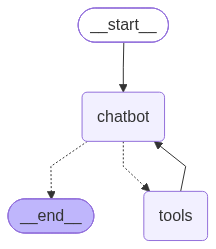

In [15]:
from IPython.display import Image, display


try:
    # Merimaid 기반으로 생성된 PNG 그래프를 출력
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # 시각화에 필요한 의존성 패키지가 없다면 예외 처리
    pass

In [16]:
def stream_graph_updates(user_input: str):
    for event in graph.stream({"messages": [{"role": "user", "content": user_input}]}):
        for value in event.values():
            print("Assistant:", value["messages"][-1].content)

In [17]:
while True:
    user_input = input("User: ")
    if user_input.lower() in ["quit", "exit", "q"]:
        print("Goodbye!")
        break


    stream_graph_updates(user_input)

Assistant: 안녕하세요! 무엇을 도와드릴까요? 😊
Assistant: 
Assistant: {"query": "오늘 대구 날씨", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://freemeteo.kr/weather/daegu-/daily-forecast/today?gid=9035841&language=korean&country=south-korea", "title": "대구 오늘 날씨 | freemeteo.kr", "score": 0.9590777, "content": "### 대구 : 악천후에 대한 경고\n\n비 오고 천둥 확률\n\n### 비 오고 천둥 확률\n\n악천후 예상됨:  2026년 9월 2일 수요일 밤\n\n# 대구 날씨 오늘\n\n29°C\n\n부분적으로 흐린 하늘\n\n상대 습도\n\n> 10000m\n\n180° 6 km/h 6 km/h\n\n구름 조금 - 1200m, 조각 구름 - 6100m\n\n최신 통보 62m 전  \n(19:00 현지 시간)\n\n## 대구 : 오늘 밤\n\n15일\n\n약한 비\n\n흐림(약한 소나기 )\n\n바람\n\n154°5 km/h\n\n강수량\n\n1.6 mm\n\n습도\n\n89 %- 95 %\n\n기압\n\n1011.8 mb- 1012.1 mb\n\n## 기온: 향후 24시간\n\n## 대구 : 시간별 예보\n\n시간별\n\n기온\n\n바람\n\n강수량\n\n00:00\n\n약한 비\n\n25°\n\n151°3 km/h\n\n00:00\n\n약한 비\n\n약한 비\n\n25°\n\n151°3 km/h\n\n1mm\n\n03:00\n\n흐린 하늘\n\n25°\n\n316°2 km/h\n\n03:00\n\n흐린 하늘\n\n흐린 하늘\n\n25° [...] 부분적으로 흐린 하늘\n\n-\n\n59%\n\n1010.8mb\n\n23°\n\n조각 구름 - 1200m, 조각 구름 - 6100m\n

In [18]:
from langgraph.checkpoint.memory import MemorySaver


memory = MemorySaver()

In [19]:
graph = graph_builder.compile(checkpointer=memory)

In [20]:
config = {"configurable": {"thread_id": "1"}}
user_input = "안녕하세요! 제 이름은 랭체인입니다."

events = graph.stream(
    {"messages": [{"role": "user", "content": user_input}]},
    config,
    stream_mode = "values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

안녕하세요! 제 이름은 랭체인입니다.
================================== Ai Message ==================================

안녕하세요, 랭체인님! 만나서 반갑습니다. 무엇을 도와드릴까요? 😊


In [21]:
user_input = "내 이름이 뭐였나요?"

events = graph.stream(
    {"messages": [{"role": "user", "content": user_input}]},
    config,
    stream_mode = "values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

내 이름이 뭐였나요?
================================== Ai Message ==================================

당신의 이름은 "랭체인"입니다! 😊  
다른 궁금한 점이나 도움이 필요한 것이 있으면 말씀해 주세요.


In [22]:
snapshot = graph.get_state(config)
print(snapshot)

StateSnapshot(values={'messages': [HumanMessage(content='안녕하세요! 제 이름은 랭체인입니다.', additional_kwargs={}, response_metadata={}, id='18c07e7a-c8df-4e9d-ba66-3f1f347b7e17'), AIMessage(content='안녕하세요, 랭체인님! 만나서 반갑습니다. 무엇을 도와드릴까요? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 1199, 'total_tokens': 1224, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1024, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_b50162a62f', 'id': 'chatcmpl-EdTdHCA1tNARPbkBUrIIki2wldoAQ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17bbd-ecb3-73f6-b0c8-52ff2911ac42-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'

In [23]:
snapshot.next

()

In [24]:
snapshot.values

{'messages': [HumanMessage(content='안녕하세요! 제 이름은 랭체인입니다.', additional_kwargs={}, response_metadata={}, id='18c07e7a-c8df-4e9d-ba66-3f1f347b7e17'),
  AIMessage(content='안녕하세요, 랭체인님! 만나서 반갑습니다. 무엇을 도와드릴까요? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 1199, 'total_tokens': 1224, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1024, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_b50162a62f', 'id': 'chatcmpl-EdTdHCA1tNARPbkBUrIIki2wldoAQ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17bbd-ecb3-73f6-b0c8-52ff2911ac42-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1199